# Figure 4: deterministic VAE reconstructions of held-out surfaces

Section 4.4, `fig:vae_three_reconstructions`. Deterministic
reconstructions of held-out surfaces of increasing complexity: input,
reconstruction at the encoder mean, and residual, for rows of 1, 3 and
10 spots, with the area-adjusted structural similarity beneath each
reconstruction and the bottom row at the 5th percentile of
reconstruction quality.

The sample is the 5000 surfaces the holdout run scored, so the VAE
figures and the Section 7 figures describe one sample. The VAE is
observer-independent, so the weighting is whole-sphere
(`ssim_aa_full`), per `docs/conventions.md` section 11.

## Imports

In [1]:
from _setup import *

from starspot_sbi.pipeline import decode_ceiling_coeffs

## Setup

The sample, the rows the caption asks for, and the percentile its
bottom-row rule names.

In [2]:
import torch

DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
SAMPLE_FAMILY = 'phot_axay'

# The caption's rows. The first two sit at the median SSIM of their spot count;
# the last is near the population percentile below, which is the caption's
# bottom-row rule applied at fixed spot count.
SPOT_COUNTS = (1, 3)
LOW_COUNT = 10
LOW_PCTL = 5

# Which surface each row shows, without moving where it sits in the quality
# distribution: a row is drawn at random from the PICK_POOL surfaces whose SSIM
# is closest to that row's target, so the caption's claim holds whatever the
# seeds are. One seed per row, chosen by eye: row 1 from seed 5, row 2 from
# seed 2, row 3 from seed 4. FIG04_ROW_SEED overrides all three with a single
# value, which is how whole seeds were browsed.
ROW_SEEDS = (5, 2, 4)
PICK_POOL = 25
if 'FIG04_ROW_SEED' in os.environ:
    ROW_SEEDS = (int(os.environ['FIG04_ROW_SEED']),) * 3

# Only the 5000-surface SSIM population is cached: it is what costs a VAE pass
# over the whole sample. The three chosen surfaces are re-decoded on the fly,
# so changing a seed costs three decodes rather than five thousand.
CACHE = os.path.join(CACHES, 'fig04_ssim.npz')

## Selecting the sample

The 5000 surfaces the run scored, with the pools the three rows are
drawn from.

In [3]:
idx = load_metrics(SAMPLE_FAMILY)['idx'].values
n_spots = load_meta().loc[idx, 'n_spots'].values
coeffs = np.stack([np.load(os.path.join(HOLDOUT, 'surfaces',
                                        f'surface_{i:07d}.npy'))
                   for i in idx])
print(f'{len(idx)} holdout surfaces, the same 5000 the run scored')
for want in SPOT_COUNTS + (LOW_COUNT,):
    print(f'  {(n_spots == want).sum():>4} surfaces with {want} spots')

5000 holdout surfaces, the same 5000 the run scored
   504 surfaces with 1 spots
   445 surfaces with 3 spots
   438 surfaces with 10 spots


## Inference

Reconstructs every surface at the encoder mean, scores it, and
resolves the three rows.

In [4]:
def score_all():
    """Reconstruct all 5000 at the encoder mean and score them."""
    vae, stats = load_autoencoder(device=DEVICE)
    rec = decode_ceiling_coeffs(coeffs, vae, stats, device=DEVICE)
    truth_real = np.stack([coeffs_to_real(c) for c in coeffs])
    timgs = render_draws(truth_real, device=DEVICE)
    rimgs = render_draws(rec, device=DEVICE)
    return np.array([metrics.ssim_aa_full(timgs[k], rimgs[k])
                     for k in range(len(idx))])


os.makedirs(CACHES, exist_ok=True)
z = np.load(CACHE) if os.path.exists(CACHE) else None
# the guard checks the scored population, not just that a file is there, so a
# different run or sample size recomputes instead of being silently reused
if z is not None and z['ssim'].size == len(idx):
    ssim = z['ssim']
    print(f'SSIM population read from {os.path.relpath(CACHE, REPO)}')
else:
    ssim = score_all()
    np.savez(CACHE, ssim=ssim)
    print(f'SSIM population written to {os.path.relpath(CACHE, REPO)}')
pctl = float(np.percentile(ssim, LOW_PCTL))
print(f'ssim_aa_full over {ssim.size} surfaces: median '
      f'{np.median(ssim):.4f}, {LOW_PCTL}th percentile {pctl:.4f} '
      f'(grid {GRID[0]} x {GRID[1]})')

SSIM population read from caches/fig04_ssim.npz
ssim_aa_full over 5000 surfaces: median 0.9879, 5th percentile 0.9667 (grid 120 x 240)


In [5]:
def choose_rows(seeds):
    """
    One surface per row, drawn from the PICK_POOL nearest that row's target.

    Row r is the pick that seeds[r] produces *at position r*. Within one seed
    the three rows come from a single stream, so the second and third draws
    depend on the ones before them; replaying the stream up to position r and
    keeping only that draw is what makes a per-row triple select exactly the
    rows seen when browsing whole seeds.
    """
    targets = [(w, None) for w in SPOT_COUNTS] + [(LOW_COUNT, pctl)]
    picked = []
    for r, seed in enumerate(seeds):
        rng = np.random.default_rng(seed)
        for want, target in targets[:r + 1]:
            pool = np.where(n_spots == want)[0]
            aim = np.median(ssim[pool]) if target is None else target
            near = pool[np.argsort(np.abs(ssim[pool] - aim))[:PICK_POOL]]
            pick = int(rng.choice(near))
        picked.append(pick)
    return np.array(picked)


rows = choose_rows(ROW_SEEDS)
row_idx, row_nspots, row_ssim = idx[rows], n_spots[rows], ssim[rows]

# only the three chosen surfaces go through the VAE again
vae, stats = load_autoencoder(device=DEVICE)
sel = coeffs[rows]
row_true = render_draws(np.stack([coeffs_to_real(c) for c in sel]),
                        device=DEVICE)
row_rec = render_draws(decode_ceiling_coeffs(sel, vae, stats, device=DEVICE),
                       device=DEVICE)

print(f'row seeds {ROW_SEEDS}, drawn from the {PICK_POOL} nearest each target')
for r in range(3):
    print(f'  surface_idx {row_idx[r]}: {row_nspots[r]} spots, '
          f'ssim {row_ssim[r]:.4f}')

/home/conaire/miniconda3/envs/paper2_gpu/lib/python3.12/site-packages/torch/nn/modules/transformer.py:385: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  warnings.warn(


row seeds (5, 2, 4), drawn from the 25 nearest each target
  surface_idx 63863: 1 spots, ssim 0.9984
  surface_idx 77515: 3 spots, ssim 0.9948
  surface_idx 63764: 10 spots, ssim 0.9661


## Plotting

Draws the figure from the names bound above.

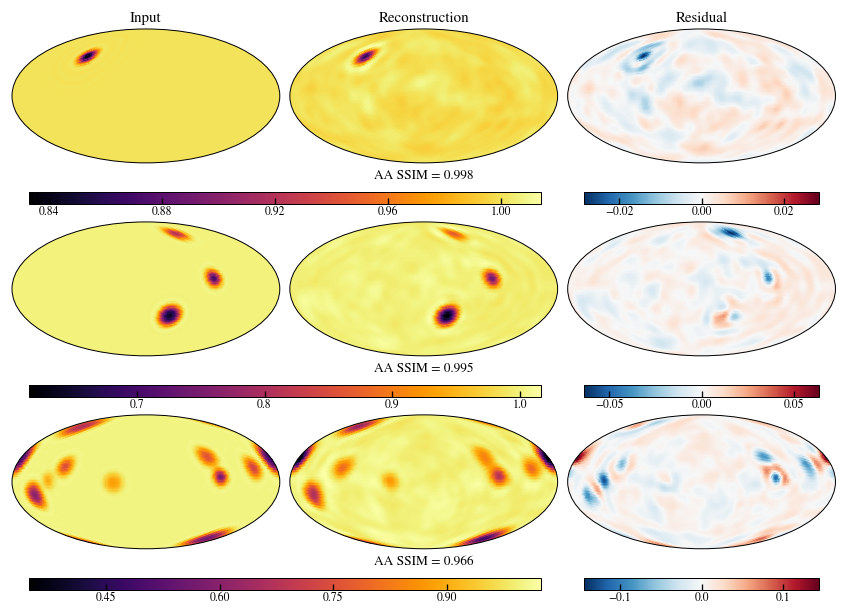

In [6]:
# Explicit geometry rather than a layout engine. The maps are aspect-locked
# ellipses and each row carries two colorbars of different widths, which the
# constrained-layout engine resizes independently: the wide one gets shrunk to
# satisfy the colorbar Axes' own aspect, and the two end up at different heights
# separated only by the narrow inter-column gap. Placing every Axes by hand
# makes the row geometry exact and identical across rows.
FIG_H = 0.72            # figure height as a fraction of its width
MARGIN_X = 0.008        # left and right margins
COL_GAP = 0.012         # between map columns
CBAR_H = 0.020          # colorbar height
CBAR_INSET = 0.02       # trimmed from each end of a colorbar
GAP_MAP_CBAR = 0.048    # map bottom to colorbar top, holds the AA SSIM line
GAP_ROWS = 0.030        # colorbar bottom to the next map
TOP = 0.955             # below the column headers

fig = plt.figure(figsize=(WIDE, WIDE * FIG_H))
fig.set_layout_engine('none')

WM = (1 - 2 * MARGIN_X - 2 * COL_GAP) / 3      # map width
HM = WM / (2 * FIG_H)                          # a 2:1 ellipse, in figure units
COL_X = [MARGIN_X + c * (WM + COL_GAP) for c in range(3)]

y_top = TOP
for r in range(3):
    truth, recon = row_true[r], row_rec[r]
    resid = truth - recon
    # shared limits across input and reconstruction, so the pair is comparable
    # by eye and the single colorbar beneath them is honest
    vmin = min(truth.min(), recon.min())
    vmax = max(truth.max(), recon.max())
    rmax = np.abs(resid).max()

    y_map = y_top - HM
    ax = [fig.add_axes([COL_X[c], y_map, WM, HM], **MAP_KW) for c in range(3)]
    m_int = draw_map(ax[0], truth, vmin=vmin, vmax=vmax)
    draw_map(ax[1], recon, vmin=vmin, vmax=vmax)
    m_res = draw_map(ax[2], resid, cmap='RdBu_r', vmin=-rmax, vmax=rmax)

    y_cb = y_map - GAP_MAP_CBAR - CBAR_H
    spans = ((m_int, COL_X[0], 2 * WM + COL_GAP, 5),
             (m_res, COL_X[2], WM, 3))
    for mesh, x0, width, nbins in spans:
        cax = fig.add_axes([x0 + CBAR_INSET, y_cb,
                            width - 2 * CBAR_INSET, CBAR_H])
        cb = fig.colorbar(mesh, cax=cax, orientation='horizontal')
        cb.ax.xaxis.set_major_locator(mpl.ticker.MaxNLocator(nbins=nbins))
        cb.ax.tick_params(labelsize=7, pad=1.5)

    fig.text(COL_X[1] + WM / 2, y_map - 0.012,
             f'AA SSIM = {row_ssim[r]:.3f}',
             ha='center', va='top', fontsize=8)

    if r == 0:
        for a, label in zip(ax, ('Input', 'Reconstruction', 'Residual')):
            a.set_title(label, fontsize=9, pad=4)
    y_top = y_cb - GAP_ROWS

## Saving and caption numbers

Writes the pdf and png, then prints the numbers the figure and the
Section 4.4 text quote.

In [7]:
save_fig(fig, 'fig04_vae_three_reconstructions')
print(f'render grid {GRID[0]} x {GRID[1]}; whole-sphere area weighting')
print(f'row seeds {ROW_SEEDS}, pick pool {PICK_POOL}')
for r in range(3):
    print(f'row: surface_idx {row_idx[r]}, {row_nspots[r]} spots, '
          f'ssim_aa_full {row_ssim[r]:.4f}')
print(f'lowest quoted row against the population {LOW_PCTL}th '
      f'percentile {pctl:.4f}')
print(f'ssim_aa_full is above {row_ssim.min():.3f} in every row')

wrote notebooks/paper/figs/fig04_vae_three_reconstructions.pdf, notebooks/paper/figs/fig04_vae_three_reconstructions.png
render grid 120 x 240; whole-sphere area weighting
row seeds (5, 2, 4), pick pool 25
row: surface_idx 63863, 1 spots, ssim_aa_full 0.9984
row: surface_idx 77515, 3 spots, ssim_aa_full 0.9948
row: surface_idx 63764, 10 spots, ssim_aa_full 0.9661
lowest quoted row against the population 5th percentile 0.9667
ssim_aa_full is above 0.966 in every row
